# EP10｜iPhone Duo 螢幕有玻璃，為什麼摺得起來？摺痕怎麼來的

像素腦底加！這是影片裡的「摺疊螢幕計算機」和「摺痕模擬器」，按上方的 **執行階段 → 全部執行**（或每格按 ▶️）就能自己跑一遍。

我們會算：玻璃彎曲時外側被拉長多少、玻璃最多能多厚、分層為什麼好彎、U 形和水滴形鉸鏈差多少，
最後模擬一隻貓的倒影被 0.01 毫米的摺痕扭彎，再試試霧面能把摺痕藏掉多少。

⚠️ 這些都是簡化的示意模型：鉸鏈尺寸、玻璃能撐的 1% 都是假設，不是哪一支手機的實際規格。

📺 影片：[youtube.com/@pixelbraintw](https://www.youtube.com/@pixelbraintw)

## 0. 準備：載入套件、下載一張貓咪照片（CC0 授權，作者 AdinaVoicu，Wikimedia Commons）

In [1]:
import os, urllib.request
import matplotlib.pyplot as plt
from PIL import Image
import numpy as np
from scipy.ndimage import gaussian_filter, map_coordinates

if not os.path.exists("cat.png"):
    urllib.request.urlretrieve("https://raw.githubusercontent.com/pixelbraintw/pixelbrain-code/main/ep10-foldable-screen/cat.png", "cat.png")

def show(*imgs, titles=None):
    fig, axes = plt.subplots(1, len(imgs), figsize=(5 * len(imgs), 5))
    for i, (ax, im) in enumerate(zip(np.atleast_1d(axes), imgs)):
        ax.imshow(im, cmap="gray", vmin=0, vmax=1)
        if titles: ax.set_title(titles[i])
        ax.axis("off")
    plt.show()

## 1. 彎曲時外側被拉長多少

彎起來的時候，外側繞大圈被拉長、內側繞小圈被壓短，正中間那層長度不變。
外側離中間的距離是厚度的一半，所以拉長的比例（應變）≈ 厚度的一半 ÷ 彎曲半徑。

In [2]:
def strain(t, R):
    return t / (2 * R)

for t in [0.5, 0.1, 0.03]:
    print(f"{t} mm 厚，彎成半徑 2 mm：外側拉長 {strain(t, 2):.2%}")

0.5 mm 厚，彎成半徑 2 mm：外側拉長 12.50%
0.1 mm 厚，彎成半徑 2 mm：外側拉長 2.50%
0.03 mm 厚，彎成半徑 2 mm：外側拉長 0.75%


## 2. 玻璃最多能多厚？

一般玻璃大約拉長千分之一（0.1%）就可能裂。超薄玻璃經過化學強化，能撐住更多；這裡的 1% 是**假設的示意門檻**。

In [3]:
for limit in [0.001, 0.01]:
    print(f"最多拉長 {limit:.1%}：彎成半徑 2 mm，玻璃最多 {2 * 2 * limit:.3f} mm 厚")

最多拉長 0.1%：彎成半徑 2 mm，玻璃最多 0.004 mm 厚
最多拉長 1.0%：彎成半徑 2 mm，玻璃最多 0.040 mm 厚


## 3. 同樣 0.4 mm，分成好幾層（理想情況：每層都能自由滑動）

In [4]:
stack = 0.4
for n in [1, 2, 4, 8]:
    print(f"分成 {n} 層：每層拉長 {strain(stack / n, 2):.2%}")

分成 1 層：每層拉長 10.00%
分成 2 層：每層拉長 5.00%
分成 4 層：每層拉長 2.50%
分成 8 層：每層拉長 1.25%


## 4. 對摺 180 度，外層比內層多走多遠？（摺一本書，書口會變斜）

In [5]:
gap = 0.1   # 兩層的中心相距 0.1 mm
print(f"外層比內層多走 {np.pi * gap:.2f} mm")
print(f"疊 10 層，最外和最內差 {np.pi * gap * 9:.2f} mm")

外層比內層多走 0.31 mm
疊 10 層，最外和最內差 2.83 mm


## 5. U 形和水滴形鉸鏈（示意尺寸）

In [6]:
u_shape = strain(0.03, 1.5)   # 闔起來留 3 mm 的縫：U 形半徑 1.5 mm
drop = strain(0.03, 3.0)      # 水滴形：鉸鏈裡的大圓半徑 3 mm
print(f"U 形 {u_shape:.2%}，水滴形 {drop:.2%}")

U 形 1.00%，水滴形 0.50%


## 6. 0.01 mm 深的摺痕，表面斜幾度？

鏡面斜 θ，反射光就轉 2θ（反射定律）。

最斜 0.23 度，倒影就轉 0.46 度


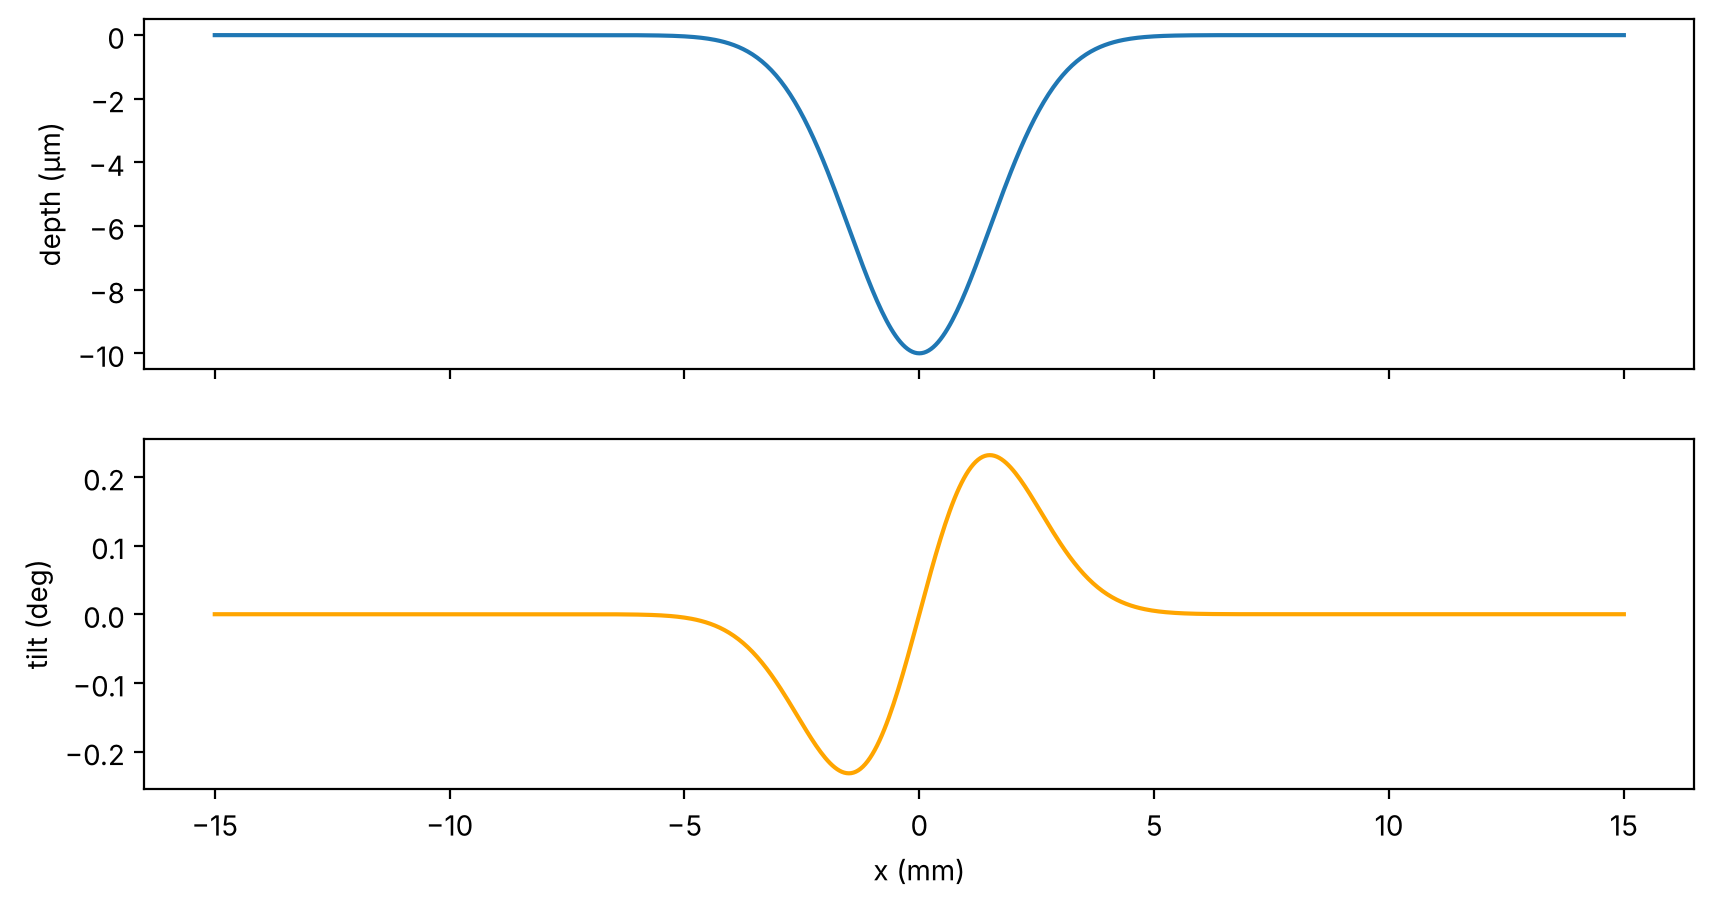

In [7]:
x = np.linspace(-15, 15, 601)                  # 螢幕上的位置（mm）
h = -0.01 * np.exp(-x**2 / (2 * 1.5**2))       # 摺痕：中間凹下 0.01 mm
tilt = np.degrees(np.arctan(np.gradient(h, x)))
print(f"最斜 {np.abs(tilt).max():.2f} 度，倒影就轉 {2 * np.abs(tilt).max():.2f} 度")

fig, ax = plt.subplots(2, 1, figsize=(10, 5), sharex=True)
ax[0].plot(x, h * 1000); ax[0].set_ylabel("depth (µm)")
ax[1].plot(x, tilt, color="orange"); ax[1].set_ylabel("tilt (deg)"); ax[1].set_xlabel("x (mm)")
plt.show()

## 7. 倒影被摺痕扭彎（換成你自己的照片也可以）

最多移動 2.4 mm


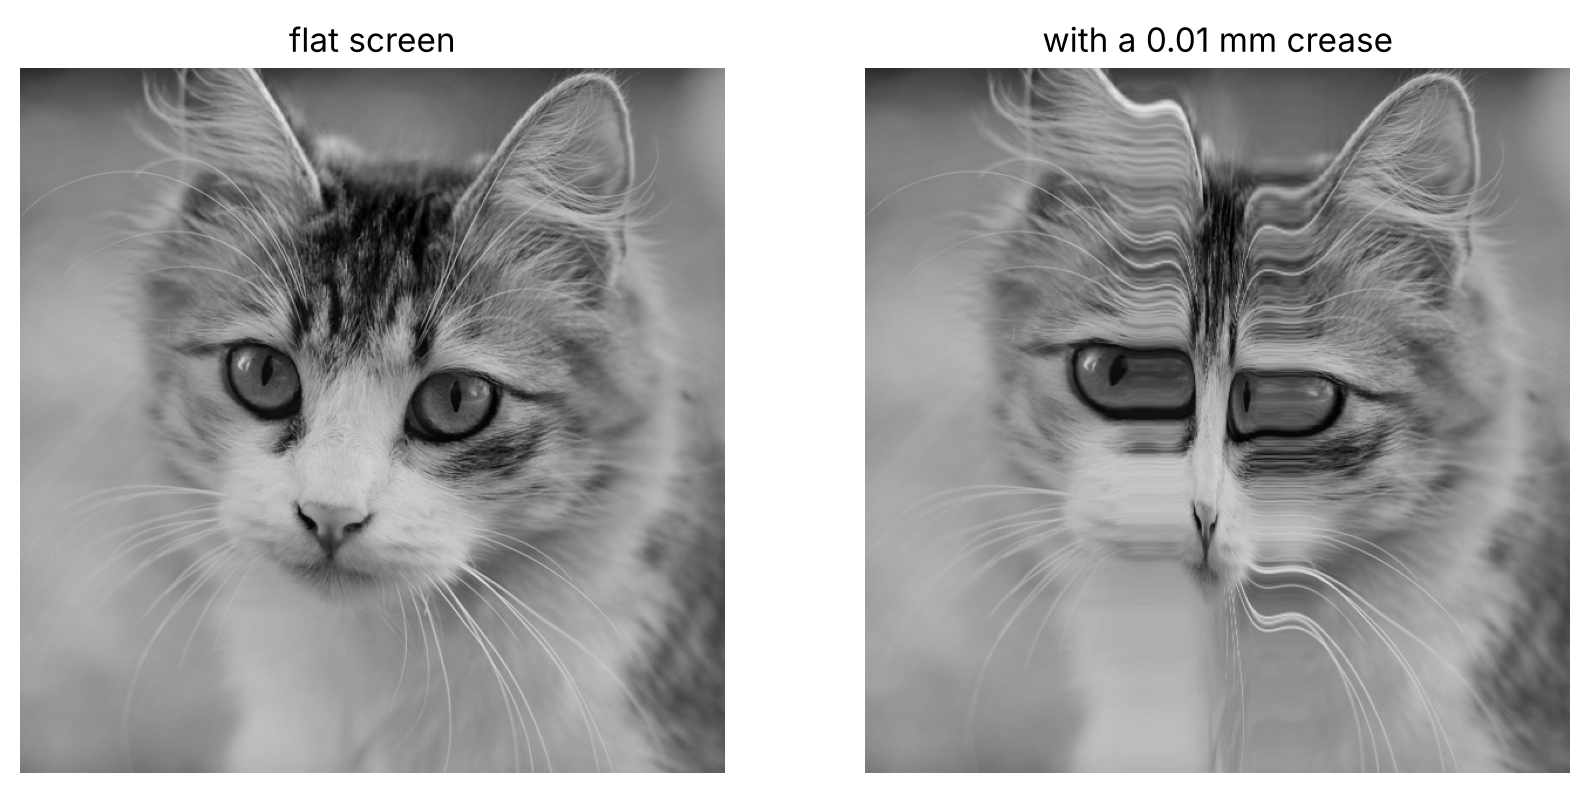

In [8]:
def reflect(img, h, L=300):
    """螢幕上每一點斜 θ，倒影就轉 2θ；L 是倒影裡的東西離螢幕多遠（mm）"""
    shift = 2 * np.gradient(h, x) * L * 20     # 換成像素（1 mm = 20 像素）
    rows, cols = np.mgrid[0:img.shape[0], 0:img.shape[1]].astype(float)
    return map_coordinates(img, [rows, cols + shift[None, :]], order=1, mode="nearest")

cat = np.array(Image.open("cat.png").convert("L").resize((601, 601))) / 255
flat, dent = reflect(cat, 0 * h), reflect(cat, h)
print(f"最多移動 {np.abs(2 * np.gradient(h, x) * 300).max():.1f} mm")
show(flat, dent, titles=["flat screen", "with a 0.01 mm crease"])

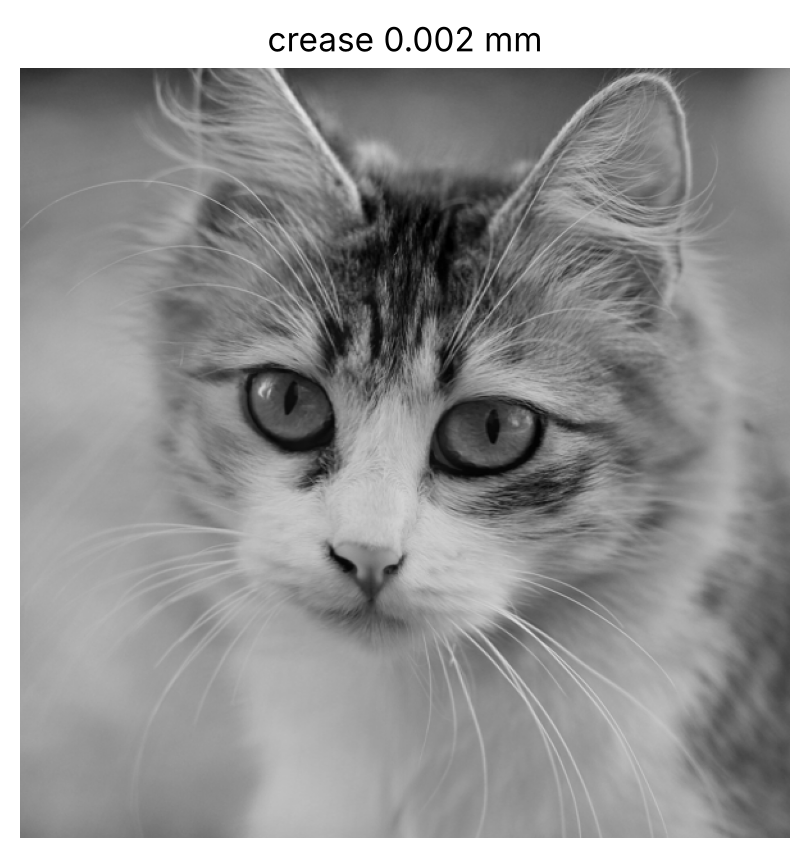

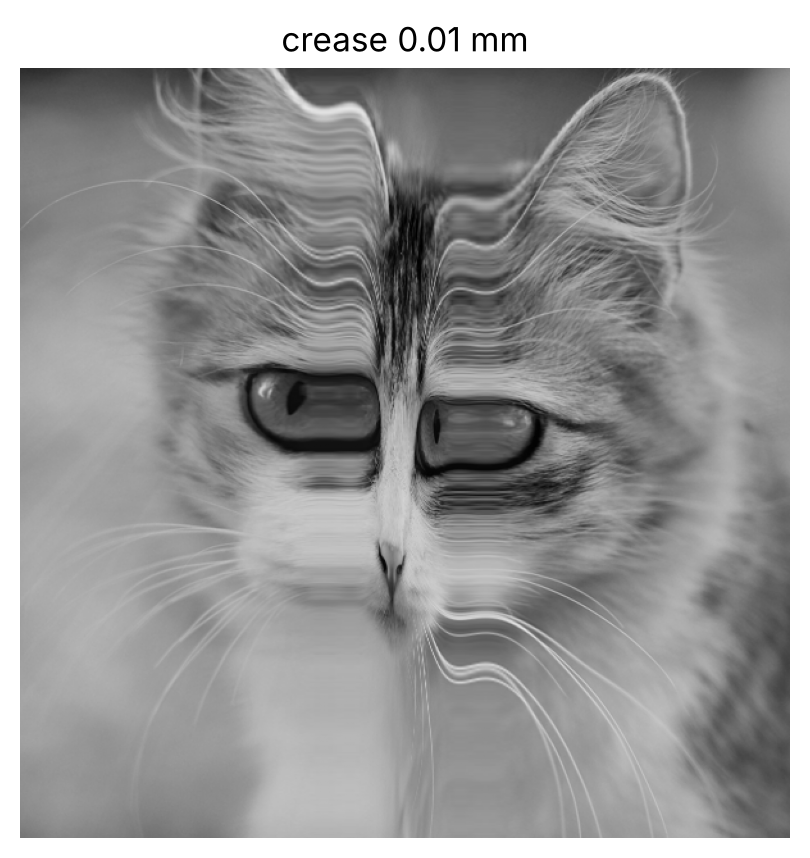

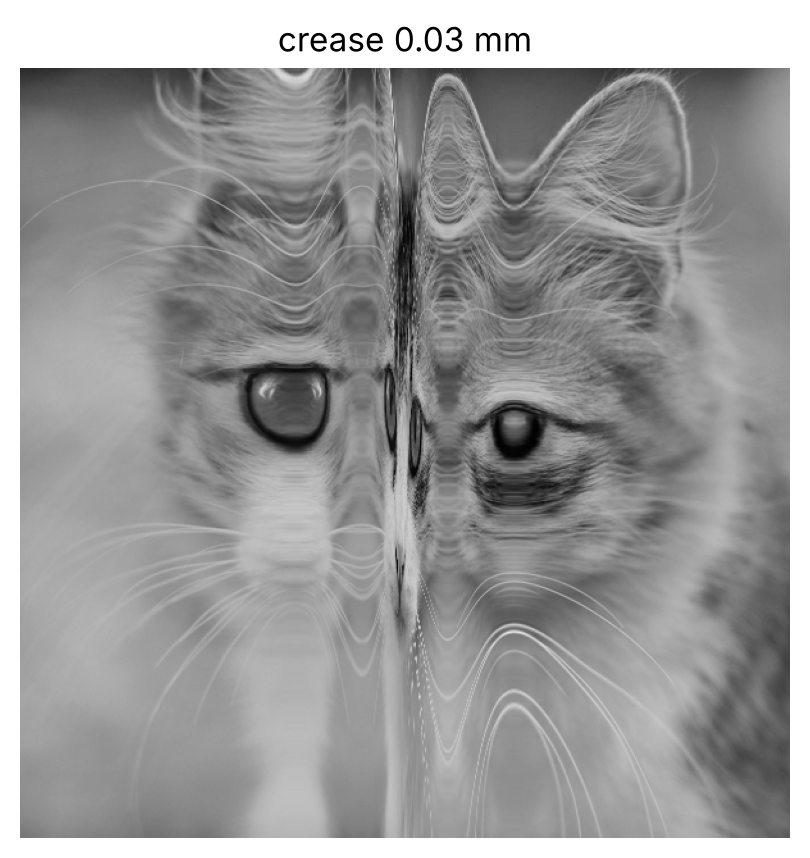

In [9]:
for d in [0.002, 0.01, 0.03]:
    show(reflect(cat, -d * np.exp(-x**2 / (2 * 1.5**2))), titles=[f"crease {d} mm"])

## 8. 霧面把反光打散（用模糊模擬散射）

摺痕造成的差別：亮面 9.0，霧面 6.3


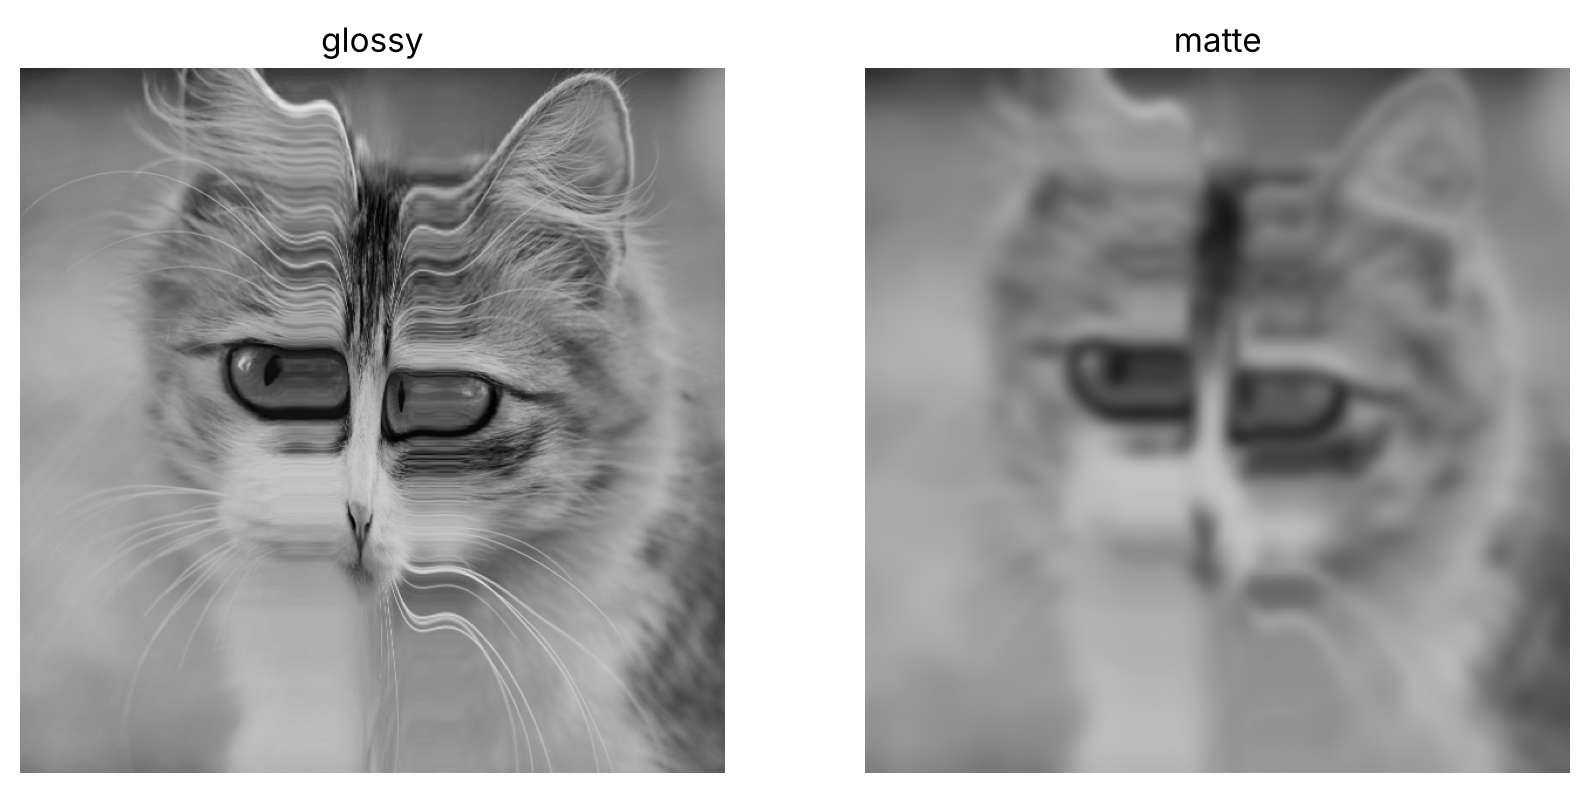

In [10]:
def matte(img, s=6):
    return gaussian_filter(img, s)

glossy = np.abs(dent - flat).mean() * 255
frosted = np.abs(matte(dent) - matte(flat)).mean() * 255
print(f"摺痕造成的差別：亮面 {glossy:.1f}，霧面 {frosted:.1f}")
show(dent, matte(dent), titles=["glossy", "matte"])

## 🧪 自己玩玩看

1. 把 `strain(0.03, 2)` 的半徑改成 1，拉長的比例會變多少？
2. 把摺痕的寬度 `1.5` 改成 `3`（同樣 0.01 mm 深，但比較寬），倒影還會扭得那麼厲害嗎？為什麼？
3. 把 `matte(img, s=6)` 的 `s` 改大，霧面能把摺痕藏掉更多嗎？代價是什麼？
4. 上傳你自己的照片（左邊資料夾圖示 → 上傳），把 `cat.png` 換成你的檔名再跑一次。

有問題歡迎到影片留言區問像素腦！